# 📌 C 프로그램 전체 진행과정 살펴보기
## `C프로그래밍 진행과정`

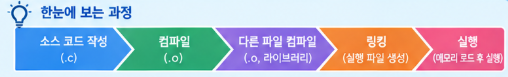  

1. 소스 작성(.c)
2. 컴파일(어셈블리어: .s > 기계어: .o)
3. 링킹
4. 실행가능한 파일(.exe)


<div style="background-color: #f9f9a9; padding: 2px; border-radius: 1px;">
  &ensp;
 환경구성
</div>

In [ ]:
%pwd
#현재 위치 확인 

In [ ]:
# (선수조건) 프로젝트 생성(폴더 생성) : project1
!mkdir project1

<div style="background-color: #f9f9a9; padding: 2px; border-radius: 1px;">
  &ensp;#1
</div>

## 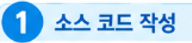
### 🔹 1. `hello.c` : **C 소스 코드 파일**

* **설명**: 사람이 작성한 C 언어 코드.
* **내용 예시**:

In [ ]:
%%writefile project1/hello.c
//1. 프로젝트내에 C 파일 생성: project1/hello.c 
#include <stdio.h>
int main(){
    printf("Hello, world !!!");
    return 0;
}

<div style="background-color: #f9f9a9; padding: 2px; border-radius: 1px;">
  &ensp;#2
</div>

## 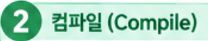
### 🔹 2-1. `hello.s` : **어셈블리 코드 파일**

* **설명**: C 코드를 어셈블리어로 번역한 중간 코드.
* **명령어 예시**:

```bash
gcc -S hello.c -o hello.s
```

* **내용 일부 예시** (간략화된 형태):

```asm
	.file	"hello.c"
	.section	.rodata
.LC0:
	.string	"Hello, world!"
	.text
	.globl	main
main:
	pushq	%rbp
	movq	%rsp, %rbp
	...
```

* **목적**: C 코드를 사람이 읽을 수 있는 기계 가까운 언어로 변환.


In [ ]:
#2. 프로젝트내에  C 파일을 어셈블리어로 변환( hello.c --> hello.s ) 
#명령 옵션: -S
!gcc -S project1/hello.c -o project1/hello.s

In [ ]:
#2. 프로젝트내에 어셈블리어 내용 확인(hello.s)
!cat project1/hello.s

<div style="background-color: #f9f9a9; padding: 2px; border-radius: 1px;">
  &ensp;#3
</div>

### 🔹 2-2. `hello.o` : **오브젝트 파일 (목적 파일)**

* **설명**: 어셈블리 코드를 기계어(바이너리)로 번역한 파일. 아직 실행은 불가능합니다.
* **명령어 예시**:

```bash
gcc -c hello.s -o hello.o
```

* **파일 형식**: ELF, COFF 등 바이너리 포맷.
* **목적**: 컴퓨터가 이해할 수 있는 기계어 코드로 바꾸지만, 링크 전 상태.

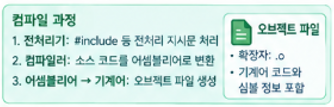

In [ ]:
#3. 어셈블리어 파일 -> 목적 파일(Object File)로 변환: C,C++ 등의 고수준 언어로 작성된 코드가 기계어로 변환된 중간 파일로 곧 최종 실행 파일을 
#   만들기 위해 **링커(Linker)**를 통해 다른 목적 파일과 결합해야 함.
# 명령 옵션: -c
!gcc -c project1/hello.s -o project1/hello.o

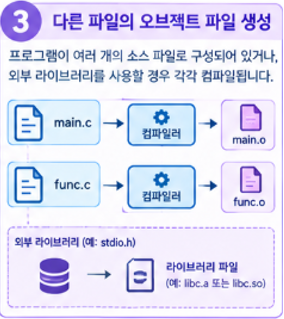

In [ ]:
# 전처리기에서 추가한 헤더파일 보기(예: stdio.h)
!ls -al /usr/include | grep stdio.h

In [ ]:
# stdio.h 내의 printf 함수 원형 보기 
!cat /usr/include/stdio.h | grep printf

In [ ]:
# 라이브러리 파일 찾기
!find /usr -name libc.* -ls

<div style="background-color: #f9f9a9; padding: 2px; border-radius: 1px;">
  &ensp;#4
</div>

## 링킹(Link)
### 🔹 3. `hello.exe` (또는 Linux에선 `hello`): **실행 파일**

* **설명**: 여러 오브젝트 파일을 연결하여 만든 완전한 실행 파일.
* **명령어 예시**:

```bash
gcc hello.o -o hello.exe    # Windows용
# 또는
gcc hello.o -o hello        # Linux용
```

* **결과**: 실행 가능한 프로그램으로서, 단독 실행이 가능.

```bash
./hello
# 출력: Hello, world!
```

In [ ]:
#4. 목적 파일 -> 실행가능한 파일로 변환
!gcc project1/hello.o -o project1/hello.exe

<div style="background-color: #f9f9a9; padding: 2px; border-radius: 1px;">
  &ensp;#5
</div>

In [ ]:
#5. 실행
!./project1/hello.exe

<div style="background-color: #f9f9a9; padding: 2px; border-radius: 1px;">
  &ensp;
</div>

### 🔄 전체 흐름 요약

```
[1] hello.c      --(컴파일: C소스를 어셈블리로 변환)--> [2] hello.s     
                   gcc -S

[2] hello.s      --(어셈블: 어셀블리를 목적파일로 변환)--> [3] hello.o     
                   gcc -c

[3] hello.o      --(링킹: .o와 라이브러리를 결합하여 실행파일로 완성)----> [4] hello.exe    
                   gcc
```

---

<div style="background-color: #f9f9a9; padding: 2px; border-radius: 1px;">
  &ensp;
</div>

## 2. 다중 파일 컴파일 예시  
📂 **프로젝트 구성**

```
project2/
│── main.c  # 메인 프로그램
│── utils.c # 유틸리티 함수 
│── utils.h # 유틸리티 함수 헤더 파일
```

#### ✅ **방법 1: 목적 파일 없이 직접 컴파일 (비효율적)**  

```sh
gcc project2/main.c project2/utils.c -o project2/my_program.exe
```

- `main.c`, `utils.c` 모두 매번 다시 컴파일됨 → **비효율적**  
- 수정하지 않은 `utils.c`도 계속 컴파일해야 함.

#### ✅ **방법 2: 목적 파일을 활용하여 컴파일 (효율적)**  

```sh
gcc -c project2/main.c -o project2/main.o
gcc -c project2/utils.c -o project2/utils.o
gcc project2/main.o project2/utils.o -o project2/my_program.exe
```

- `utils.c`가 수정되지 않으면 **다시 컴파일할 필요 없음**  
- 변경된 파일만 재컴파일하면 됨 → **빌드 속도 향상**


In [ ]:
%pwd 
#현재 위치 확인

In [ ]:
#1. 프로젝트 폴더 생성
!mkdir project2

In [ ]:
%%writefile project2/utils.h
//2-1. C프로그램 utils.h 파일 생성
#ifndef UTILS_H
#define UTILS_H
void myprintf();
#endif //UTILS_H 중복 방지를 위해

In [ ]:
%%writefile project2/utils.c
//2-2. C프로그램 utils.c 파일
#include <stdio.h>
#include "utils.h"
void myprintf(){
    printf("내가 만들 유틸리티 함수: myprintf()\n");    
}

In [ ]:
%%writefile project2/main.c
//2-3. C프로그램 main.c 파일
#include <stdio.h>
#include "utils.h"
int main(){
    printf("This is main.c\n");
    myprintf();
    return 0;
}

In [ ]:
#3. 개별 C파일을 목적 파일(.o)로 변환
!gcc -c project2/utils.c -o project2/utils.o
!gcc -c project2/main.c -o project2/main.o

In [ ]:
#4. 목적 파일을 실행가능한 파일로 링크
!gcc project2/main.o project2/utils.o -o project2/main.exe

In [ ]:
#5. 결과 확인
!./project2/main.exe